ACT N-2


les imports necessaires

In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.14.1+cpu
Device : cpu


In [57]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000



On definie le dataset d'entrainement (train=true) et du test, le (train=False) dans le test_dataset couvre les labels cible du modele, mais elle est toujours visible par nous

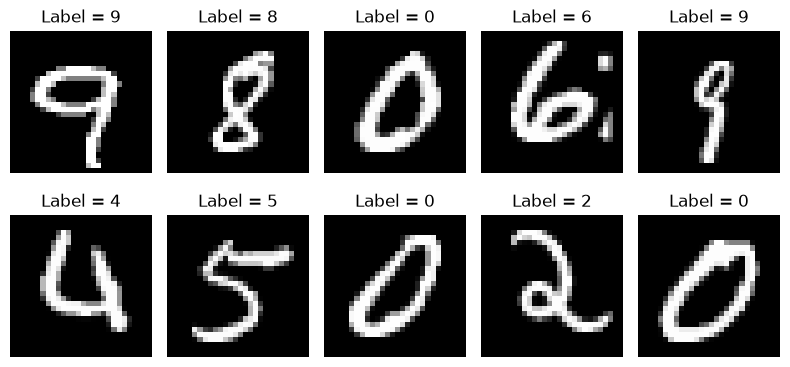

In [58]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

on visualize 2 Lignes et 5 col du dataset avec leurs labels

In [59]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

on definit un classificateur simple avec une architecture de réseau de neurones entièrement connectée.
Le modèle prend en entrée des images MNIST de taille 28x28 pixels (784 pixels au total après aplatissement) et les passe à travers deux couches linéaires avec une fonction d'activation ReLU entre elles.
La sortie finale est un vecteur de 10 dimensions correspondant aux 10 classes de chiffres (0 à 9).

In [60]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

Le CrossEntropyLoss() permit de mesurer a quel point les predictions de notre model est mauvais 

L'optimizer utilise les gradients de cette erreur pour modifier les paramètres du modèle et améliorer ses prédictions.

In [61]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4187
Epoch 2/3 - Loss = 0.1966
Epoch 3/3 - Loss = 0.1392


on peut remaarquer que le loss diminue lors le nombre des epochs augmente, cad que le modele apprend mieux

In [62]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.22%


on evalue l'accuracy de notre modele en definissant evaluate_classifier et prenant en argument le classifier et le test_loader

In [63]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

Accuracy = 96.22%


on peut aussi savoir l'accuracy in important torcheval.metrics et utilisant le metric MulticlassAccuracy, avec cette approche le model se focalise sur savoir comment distinguer entre les classes

partie 2: Auto encodeur



In [64]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

partie 2: Auto encodeur

Un autoencodeur apprend a reconstruire une image. Il comprime x en un vecteur latent z, puis reconstruit une image depuis z.

entrainement de l autoencodeur

In [65]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(f'Epoch {epoch + 1}/{epochs} | Loss: {total_loss / len(loader):.4f}')

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 | Loss: 0.0669
Epoch 2/5 | Loss: 0.0524
Epoch 3/5 | Loss: 0.0503
Epoch 4/5 | Loss: 0.0480
Epoch 5/5 | Loss: 0.0464


on visualise les reconstructions. la premiere ligne contient les vraies images et la deuxieme contient les images reconstruites.

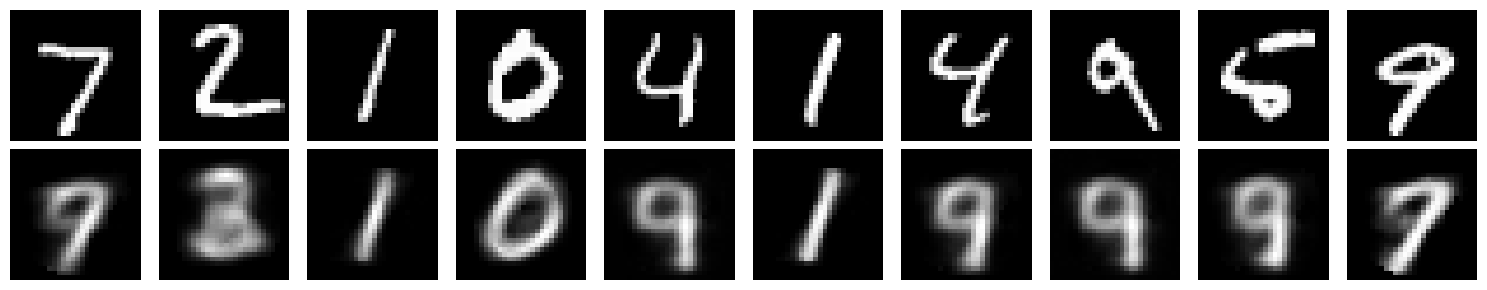

In [66]:
ae.eval()
x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap='gray')
    axes[0, i].axis('off')

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Original')
axes[1, 0].set_ylabel('Reconstruit')
plt.tight_layout()
plt.show()

visualisation de l espace latent

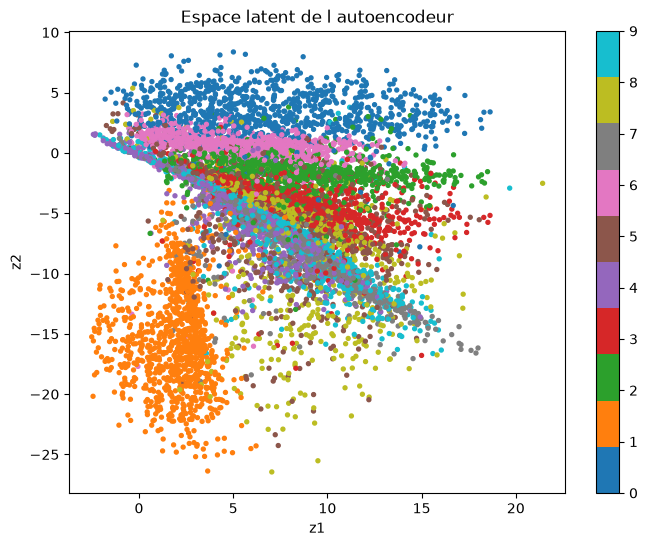

In [67]:
ae.eval()
z_values = []
labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)
        z_values.append(z.cpu())
        labels.append(y)

z_values = torch.cat(z_values).numpy()
labels = torch.cat(labels).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(z_values[:, 0], z_values[:, 1], c=labels, cmap='tab10', s=8)
plt.colorbar(scatter, ticks=range(10))
plt.xlabel('z1')
plt.ylabel('z2')
plt.title('Espace latent de l autoencodeur')
plt.show()

partie 3: VAE

Le VAE represente chaque image par une distribution dans l espace latent: une moyenne mu et une variance logvar.

In [68]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU()
        )
        self.mu = nn.Linear(32, latent_dim)
        self.logvar = nn.Linear(32, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + epsilon * std

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
  )
  (mu): Linear(in_features=32, out_features=2, bias=True)
  (logvar): Linear(in_features=32, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

fonction de perte du VAE. elle combine la reconstruction des images et la regularisation de l espace latent.

In [69]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    reconstruction = F.binary_cross_entropy(x_hat, x, reduction='sum')
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return reconstruction + beta * kl

vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

def train_vae(model, loader, epochs=10, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss = vae_loss(x_hat, x, mu, logvar, beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()

        print(f'Epoch {epoch + 1}/{epochs} | Loss: {total_loss / len(loader.dataset):.4f}')

train_vae(vae, train_loader, epochs=10)

Epoch 1/10 | Loss: 209.5879
Epoch 2/10 | Loss: 170.7836
Epoch 3/10 | Loss: 166.1246
Epoch 4/10 | Loss: 162.8198
Epoch 5/10 | Loss: 159.7911
Epoch 6/10 | Loss: 157.5394
Epoch 7/10 | Loss: 155.9233
Epoch 8/10 | Loss: 154.7454
Epoch 9/10 | Loss: 153.5981
Epoch 10/10 | Loss: 152.6164


reconstruction avec le VAE

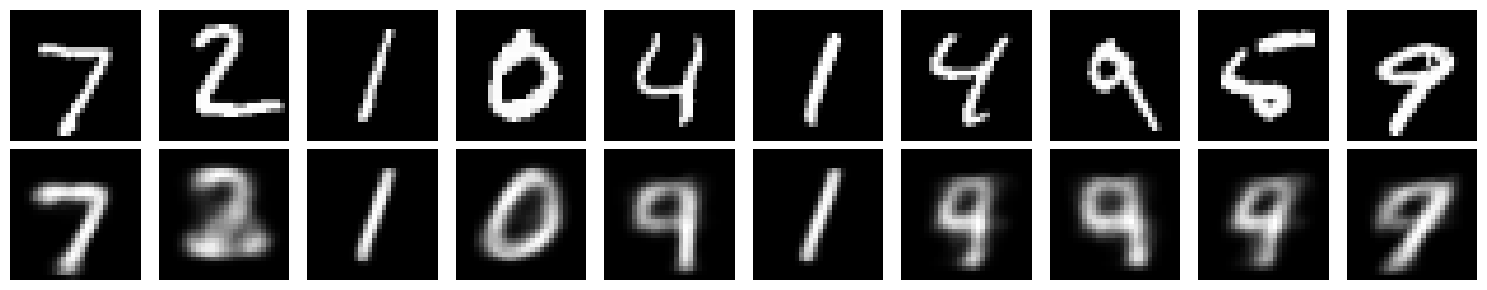

In [70]:
vae.eval()
x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap='gray')
    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].axis('off')
plt.tight_layout()
plt.show()

generation de nouvelles images avec le VAE. on tire directement des vecteurs z dans une loi normale.

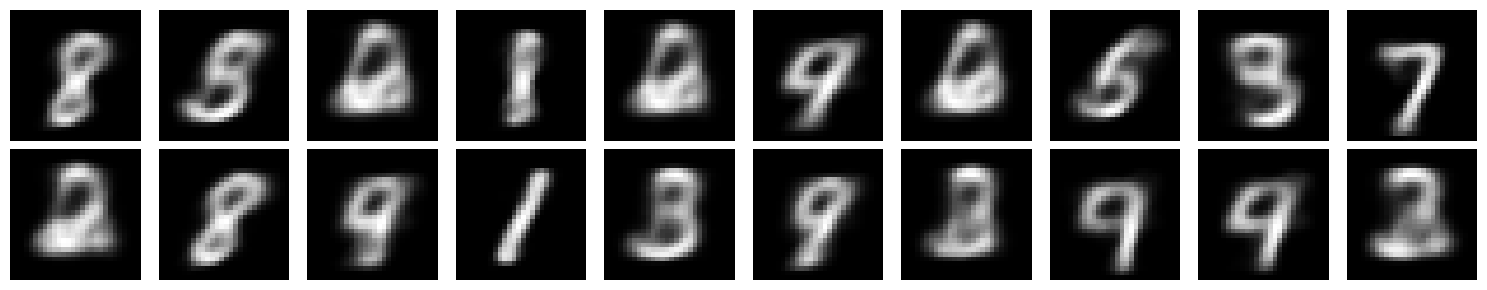

In [71]:
vae.eval()
with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.show()

partie 4: GAN

Le generateur produit des images depuis du bruit. Le discriminateur distingue les vraies images des images generees.

In [72]:
latent_dim = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.net(x)

generator = Generator().to(device)
discriminator = Discriminator().to(device)
criterion_gan = nn.BCEWithLogitsLoss()
optimizer_g = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

entrainement du GAN

In [73]:
gan_epochs = 5

for epoch in range(gan_epochs):
    loss_d_total = 0
    loss_g_total = 0

    for real, _ in train_loader:
        real = real.to(device)
        real = real * 2 - 1
        batch_size = real.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        optimizer_d.zero_grad()
        real_scores = discriminator(real)
        loss_real = criterion_gan(real_scores, real_labels)

        z = torch.randn(batch_size, latent_dim, device=device)
        fake = generator(z)
        fake_scores = discriminator(fake.detach())
        loss_fake = criterion_gan(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        optimizer_d.step()

        optimizer_g.zero_grad()
        z = torch.randn(batch_size, latent_dim, device=device)
        fake = generator(z)
        fake_scores = discriminator(fake)
        loss_g = criterion_gan(fake_scores, real_labels)
        loss_g.backward()
        optimizer_g.step()

        loss_d_total += loss_d.item()
        loss_g_total += loss_g.item()

    print(f'Epoch {epoch + 1}/{gan_epochs} | Loss D: {loss_d_total / len(train_loader):.4f} | Loss G: {loss_g_total / len(train_loader):.4f}')

Epoch 1/5 | Loss D: 0.4727 | Loss G: 1.3072
Epoch 2/5 | Loss D: 0.3460 | Loss G: 2.2024
Epoch 3/5 | Loss D: 0.3187 | Loss G: 2.4856
Epoch 4/5 | Loss D: 0.3355 | Loss G: 2.4285
Epoch 5/5 | Loss D: 0.3054 | Loss G: 2.6059


generation avec le GAN

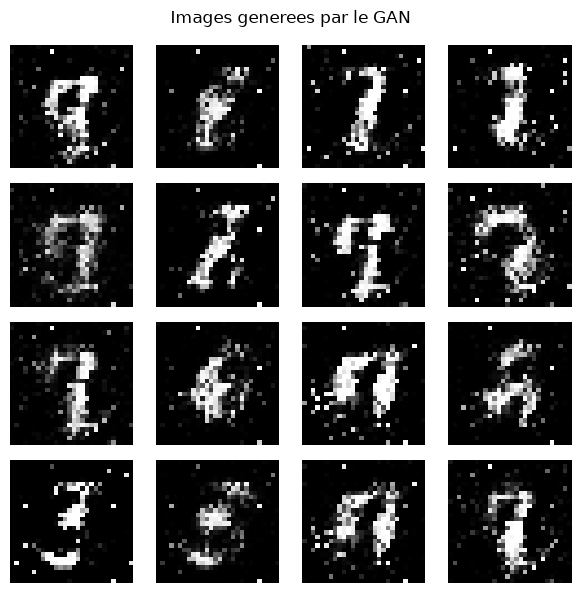

In [74]:
generator.eval()
with torch.no_grad():
    z = torch.randn(16, latent_dim, device=device)
    samples = (generator(z).cpu() + 1) / 2

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, image in zip(axes.flat, samples):
    ax.imshow(image.squeeze(), cmap='gray')
    ax.axis('off')
plt.suptitle('Images generees par le GAN')
plt.tight_layout()
plt.show()

partie 5: modele de diffusion

Le modele de diffusion ajoute progressivement du bruit a une image, puis apprend a retirer ce bruit pour generer une nouvelle image.

In [75]:
T = 100

def make_schedule(T):
    betas = torch.linspace(1e-4, 0.02, T, device=device)
    alphas = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    return betas, alphas, alpha_bars

betas, alphas, alpha_bars = make_schedule(T)

def add_noise_diffusion(x0, t):
    noise = torch.randn_like(x0)
    alpha_bar = alpha_bars[t].view(-1, 1, 1, 1)
    xt = alpha_bar.sqrt() * x0 + (1 - alpha_bar).sqrt() * noise
    return xt, noise

class DiffusionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784 + T, 256),
            nn.ReLU(),
            nn.Linear(256, 784)
        )

    def forward(self, x, t):
        batch_size = x.size(0)
        time = F.one_hot(t, num_classes=T).float()
        h = torch.cat([x.flatten(1), time], dim=1)
        return self.net(h).view(batch_size, 1, 28, 28)

diffusion_model = DiffusionMLP().to(device)
diffusion_optimizer = torch.optim.Adam(diffusion_model.parameters(), lr=1e-3)

entrainement du modele de diffusion

In [76]:
diffusion_history = []

def train_diffusion(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = (x * 2 - 1).to(device)
            t = torch.randint(0, T, (x.size(0),), device=device)
            xt, noise = add_noise_diffusion(x, t)
            predicted_noise = model(xt, t)
            loss = F.mse_loss(predicted_noise, noise)

            diffusion_optimizer.zero_grad()
            loss.backward()
            diffusion_optimizer.step()

            total_loss += loss.item()

        mean_loss = total_loss / len(loader)
        diffusion_history.append(mean_loss)
        print(f'Epoch {epoch + 1}/{epochs} | Loss: {mean_loss:.4f}')

train_diffusion(diffusion_model, train_loader, epochs=5)

Epoch 1/5 | Loss: 0.9948
Epoch 2/5 | Loss: 0.9891
Epoch 3/5 | Loss: 0.9856
Epoch 4/5 | Loss: 0.9844
Epoch 5/5 | Loss: 0.9842


generation par diffusion inverse

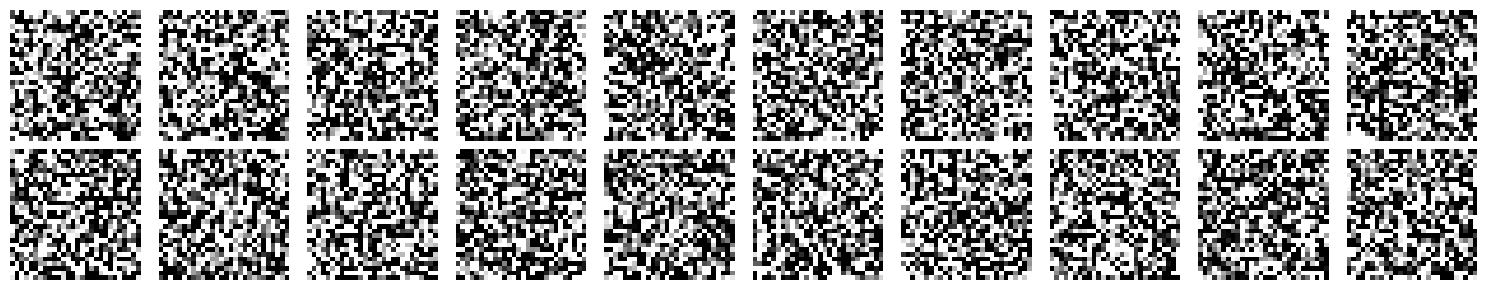

In [77]:
@torch.no_grad()
def generate_diffusion(model, n_images=20):
    model.eval()
    x = torch.randn(n_images, 1, 28, 28, device=device)

    for step in reversed(range(T)):
        t = torch.full((n_images,), step, device=device, dtype=torch.long)
        predicted_noise = model(x, t)

        beta = betas[step]
        alpha = alphas[step]
        alpha_bar = alpha_bars[step]

        x = (1 / alpha.sqrt()) * (x - (1 - alpha) / (1 - alpha_bar).sqrt() * predicted_noise)

        if step > 0:
            x = x + beta.sqrt() * torch.randn_like(x)

    return ((x + 1) / 2).clamp(0, 1).cpu()

samples = generate_diffusion(diffusion_model, 20)
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for ax, image in zip(axes.flat, samples):
    ax.imshow(image.squeeze(), cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.show()

partie 6: modele autoregressif

Un modele autoregressif predit chaque pixel a partir des pixels precedents.

Epoch 1/3 | Loss: 0.3907 | Accuracy: 76.61%
Epoch 2/3 | Loss: 0.2665 | Accuracy: 85.73%
Epoch 3/3 | Loss: 0.2223 | Accuracy: 88.73%


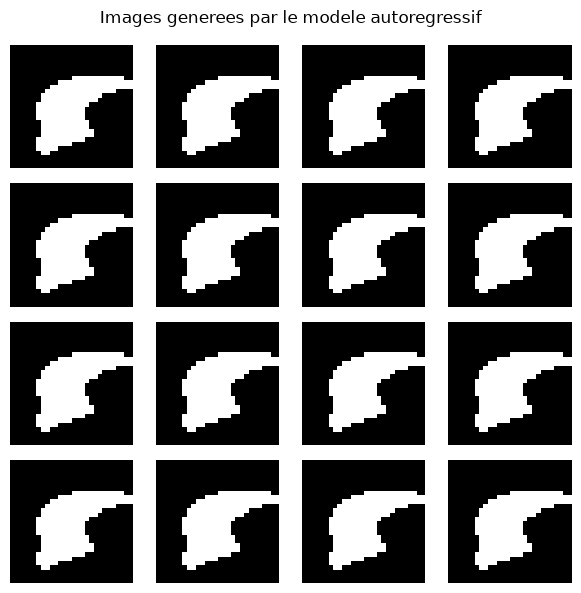

In [78]:
class PixelMLP(nn.Module):
    def __init__(self, pixel_count=786):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(pixel_count, 512),
            nn.LayerNorm(512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 2)
        )

    def forward(self, prefix):
        return self.net(prefix)

pixel_model = PixelMLP().to(device)
pixel_optimizer = torch.optim.AdamW(pixel_model.parameters(), lr=1e-3, weight_decay=1e-4)
pixel_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(pixel_optimizer, T_max=3)

pixel_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

def train_autoregressive(model, loader, epochs=3, pixels_per_image=32):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        correct = 0
        total = 0

        for x, _ in loader:
            x = x.to(device).flatten(1)
            x = (x > 0.5).long()
            batch_size = x.size(0)

            positions = torch.randint(
                0, 784,
                (batch_size, pixels_per_image),
                device=device
            )
            targets = x.gather(1, positions).reshape(-1)

            columns = torch.arange(784, device=device).view(1, 1, 784)
            prefix_mask = columns < positions.unsqueeze(-1)
            prefixes = x.unsqueeze(1).float() * prefix_mask

            rows = (positions // 28).float().div_(27).unsqueeze(-1)
            cols = (positions % 28).float().div_(27).unsqueeze(-1)
            position_features = torch.cat([rows, cols], dim=2).reshape(-1, 2)

            prefixes = torch.cat([
                prefixes.reshape(-1, 784),
                position_features
            ], dim=1)

            logits = model(prefixes)

            count0 = (targets == 0).sum()
            count1 = (targets == 1).sum()
            weights = torch.tensor([
                1.0 / max(count0.float(), 1.0),
                1.0 / max(count1.float(), 1.0)
            ], device=device)
            weights = weights / weights.sum() * 2

            loss = F.cross_entropy(logits, targets, weight=weights)

            pixel_optimizer.zero_grad(set_to_none=True)
            loss.backward()
            pixel_optimizer.step()

            total_loss += loss.item()
            correct += (logits.argmax(dim=1) == targets).sum().item()
            total += targets.numel()

        pixel_scheduler.step()
        accuracy = 100 * correct / total
        print(f'Epoch {epoch + 1}/{epochs} | Loss: {total_loss / len(loader):.4f} | Accuracy: {accuracy:.2f}%')

train_autoregressive(pixel_model, pixel_loader, epochs=3, pixels_per_image=32)

# Generate a few images pixel by pixel.
pixel_model.eval()
with torch.no_grad():
    generated = torch.zeros(16, 784, device=device)

    for step in range(784):
        rows = torch.full((16,), step // 28, device=device, dtype=torch.float32) / 27
        cols = torch.full((16,), step % 28, device=device, dtype=torch.float32) / 27
        position_features = torch.stack([rows, cols], dim=1)

        model_input = torch.cat([generated, position_features], dim=1)
        logits = pixel_model(model_input)
        generated[:, step] = logits.argmax(dim=1).float()

images = generated.view(16, 1, 28, 28).cpu()
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(), cmap='gray')
    ax.axis('off')
plt.suptitle('Images generees par le modele autoregressif')
plt.tight_layout()
plt.show()